In [ ]:
from pathlib import Path
import pandas as pd

csv_path = Path('/content/dft-road-casualty-statistics-collision-2025.csv 2')
if not csv_path.exists():
    from google.colab import files
    print('Select your original 2025 road collision CSV file.')
    uploaded = files.upload()
    csv_files = [(filename, content) for filename, content in uploaded.items()
                 if filename.lower().endswith('.csv')]
    if not csv_files:
        raise FileNotFoundError('Please upload the original road collision CSV and rerun.')
    filename, content = csv_files[0]
    csv_path.write_bytes(content)
    print('Uploaded:', filename)

df = pd.read_csv(csv_path, dtype={'collision_index': str, 'collision_ref_no': str})
print('Dataset loaded:', df.shape[0], 'rows ×', df.shape[1], 'columns')
display(df.head())


In [ ]:
print(df.columns.tolist())

display(df['collision_severity'])

display(df['number_of_vehicles'])

display(df['number_of_casualties'])

In [ ]:
total_records = len(df)

ten_percent = int(total_records * 0.10)

df_slice = df.iloc[:ten_percent]

print("Total number of records:", total_records)
print("10% of the dataset:", ten_percent)

display(df_slice)

In [ ]:
total_rows = len(df)

rows_to_show = int(total_rows * 0.10)

first_10_percent = df[:rows_to_show]

print("Total rows:", total_rows)
print("10 percent of total rows:", rows_to_show)

display(first_10_percent)

# New section

In [ ]:
for column in df.columns:

    print("\nColumn:", column)

    if pd.api.types.is_numeric_dtype(df[column]):
        print("Mean:", df[column].mean())
        print("Standard Deviation:", df[column].std())
    else:
        print("Mean: N/A")
        print("Standard Deviation: N/A")

    print("Five most repeated values:")
    print(df[column].value_counts(dropna=False).head(5))

In [ ]:
import matplotlib.pyplot as plt

df['collision_severity'].value_counts().sort_index().plot(kind='bar')

plt.title('Collision Severity')
plt.xlabel('Severity')
plt.ylabel('Number of Collisions')

plt.show()

Assessment 2

In [ ]:

import pandas as pd

df = pd.read_csv('/content/dft-road-casualty-statistics-collision-2025.csv')

print("Dataset loaded successfully!")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

display(df.head())


In [ ]:


import pandas as pd

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\n1st five records:")
display(df.head())

# Check for missing values in every column
print("\nMissing values:")
missing_data = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_data.sort_values(
    by="Missing Values",
    ascending=False
))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCollision severity:")
print(df["collision_severity"].value_counts().sort_index())


In [ ]:

columns_to_check = [
    "speed_limit",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

for column in columns_to_check:

    print("\n---------------------------")
    print("Column:", column)
    print("---------------------------")

    print(df[column].value_counts(dropna=False).sort_index())


In [ ]:

df_clean = df.copy()

category_labels = {
    "road_type": {
        1: "Roundabout",
        2: "One-way street",
        3: "Dual carriageway",
        6: "Single carriageway",
        7: "Slip road",
        9: "Unknown"
    },
    "light_conditions": {
        -1: "Missing",
        1: "Daylight",
        4: "Dark - lights lit",
        5: "Dark - lights unlit",
        6: "Dark - no lighting",
        7: "Dark - lighting unknown"
    },
    "weather_conditions": {
        1: "Fine",
        2: "Raining",
        3: "Snowing",
        4: "Fine - high winds",
        5: "Rain - high winds",
        6: "Snow - high winds",
        7: "Fog or mist",
        8: "Other",
        9: "Unknown"
    },
    "road_surface_conditions": {
        -1: "Missing",
        1: "Dry",
        2: "Wet or damp",
        3: "Snow",
        4: "Frost or ice",
        5: "Flood",
        9: "Unknown"
    },
    "urban_or_rural_area": {
        1: "Urban",
        2: "Rural",
        3: "Unallocated"
    }
}

for column, labels in category_labels.items():
    df_clean[column + "_label"] = (
        df_clean[column].map(labels).fillna("Unmapped code")
    )

print("Orig rows:", len(df))
print("Clean rows:", len(df_clean))

print("\nWeather categories:")
print(df_clean["weather_conditions_label"].value_counts())

print("\nRoad types:")
print(df_clean["road_type_label"].value_counts())

print("\nUnmapped values:")
for column in category_labels:
    label_column = column + "_label"
    print(column, (df_clean[label_column] == "Unmapped code").sum())


In [ ]:


df_clean = df.copy()

weather_labels = {
    1: "Fine",
    2: "Raining",
    3: "Snowing",
    4: "Fine with high winds",
    5: "Rain with high winds",
    6: "Snow with high winds",
    7: "Fog or mist",
    8: "Other",
    9: "Unknown"
}

severity_labels = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

df_clean["weather_label"] = (
    df_clean["weather_conditions"].map(weather_labels)
)

df_clean["severity_label"] = (
    df_clean["collision_severity"].map(severity_labels)
)

display(df_clean[
    ["weather_conditions", "weather_label",
     "collision_severity", "severity_label"]
].head(10))


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

weather_labels = {
    1: "Fine",
    2: "Rain",
    3: "Snow",
    4: "Fine with high winds",
    5: "Rain with high winds",
    6: "Snow with high winds",
    7: "Fog or mist",
    8: "Other",
    9: "Unknown"
}

weather_counts = pd.crosstab(
    df["weather_conditions"],
    df["collision_severity"]
)

weather_counts = weather_counts.reindex(
    columns=[1, 2, 3],
    fill_value=0
)

weather_counts.columns = ["Fatal", "Serious", "Slight"]

weather_counts["Total"] = weather_counts.sum(axis=1)

weather_counts["Fatal or Serious (%)"] = (
    (weather_counts["Fatal"] + weather_counts["Serious"])
    / weather_counts["Total"] * 100
).round(2)

weather_counts["Weather"] = weather_counts.index.map(
    weather_labels
)

print("Collision severity by weather conditions:")
display(weather_counts)

chart_data = weather_counts[
    (weather_counts["Total"] >= 100) &
    (weather_counts.index != 9)
].copy()

chart_data = chart_data.sort_values(
    "Fatal or Serious (%)"
)

plt.figure(figsize=(11, 6))

plt.barh(
    chart_data["Weather"],
    chart_data["Fatal or Serious (%)"]
)

plt.title("Fatal or Serious Collisions by Weather Conditions")
plt.xlabel("Fatal or Serious Collisions (%)")
plt.ylabel("Weather Conditions")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

weather_labels = {
    1: "Fine",
    2: "Rain",
    3: "Snow",
    4: "Fine with high winds",
    5: "Rain with high winds",
    6: "Snow with high winds",
    7: "Fog or mist",
    8: "Other",
    9: "Unknown"
}

fatal_accidents = df[df["collision_severity"] == 1]

fatal_weather = (
    fatal_accidents["weather_conditions"]
    .value_counts()
    .sort_index()
)

fatal_weather.index = fatal_weather.index.map(weather_labels)

fatal_weather = fatal_weather.sort_values(ascending=False)

print("Number of Fatal Collisions by Weather Conditions:")
display(fatal_weather.to_frame(name="Fatal Collisions"))

plt.figure(figsize=(11, 6))

plt.barh(
    fatal_weather.index,
    fatal_weather.values,
    color="darkred"
)

plt.title("Number of Fatal Road Collisions by Weather Conditions (2025)")
plt.xlabel("Number of Fatal Collisions")
plt.ylabel("Weather Conditions")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total fatal collisions:", len(fatal_accidents))


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

light_labels = {
    -1: "Missing",
    1: "Daylight",
    4: "Dark - lights lit",
    5: "Dark - lights unlit",
    6: "Dark - no lighting",
    7: "Dark - lighting unknown"
}

fatal_accidents = df[df["collision_severity"] == 1]

fatal_lighting = (
    fatal_accidents["light_conditions"]
    .map(light_labels)
    .fillna("Unmapped code")
    .value_counts()
    .sort_values(ascending=False)
)

print("Number of Fatal Collisions by Lighting Conditions:")
display(fatal_lighting.to_frame(name="Fatal Collisions"))

plt.figure(figsize=(11, 6))

plt.barh(
    fatal_lighting.index,
    fatal_lighting.values,
    color="darkblue"
)

plt.title("Fatal Road Collisions by Lighting Conditions in 2025")
plt.xlabel("No of Fatal Collisions")
plt.ylabel("Lighting Conditions")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("Total fatal collisions:", fatal_lighting.sum())


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt


light_labels = {
    -1: "Missing",
    1: "Daylight",
    4: "Dark - lights lit",
    5: "Dark - lights unlit",
    6: "Dark - no lighting",
    7: "Dark - lighting unknown"
}


serious_accidents = df[df["collision_severity"] == 2].copy()

serious_accidents["lighting"] = (
    serious_accidents["light_conditions"]
    .map(light_labels)
    .fillna("Unknown")
)


serious_lighting = (
    serious_accidents["lighting"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Serious Collisions by Lighting Conditions (2025)")
display(serious_lighting.to_frame(name="Serious Collisions"))

plt.figure(figsize=(11, 6))

plt.barh(
    serious_lighting.index,
    serious_lighting.values,
    color="orange"
)

plt.title("Serious Collisions by Lighting Conditions (2025)")
plt.xlabel("Number of Serious Collisions")
plt.ylabel("Lighting Conditions")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total Serious Collisions:", serious_lighting.sum())


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt

surface_labels = {
    -1: "Missing",
    1: "Dry",
    2: "Wet or damp",
    3: "Snow",
    4: "Frost or ice",
    5: "Flood",
    9: "Unknown"
}

serious_accidents = df[
    df["collision_severity"] == 2
].copy()

serious_accidents["road_surface"] = (
    serious_accidents["road_surface_conditions"]
    .map(surface_labels)
    .fillna("Unknown")
)


serious_surface = (
    serious_accidents["road_surface"]
    .value_counts()
    .sort_values(ascending=False)
)

print("Serious Collisions by Road Surface Conditions (2025)")

display(
    serious_surface.to_frame(name="Serious Collisions")
)

plt.figure(figsize=(11, 6))

plt.barh(
    serious_surface.index,
    serious_surface.values,
    color="orange"
)

plt.title("Serious Collisions by Road Surface Conditions (2025)")
plt.xlabel("Number of Serious Collisions")
plt.ylabel("Road Surface Conditions")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total Serious Collisions:", serious_surface.sum())


Steamlit App

In [ ]:
!pip install -q streamlit pandas matplotlib plotly scikit-learn


In [ ]:

import subprocess
import sys
import os

app_path = "/content/CarApp.py"

if os.path.exists(app_path):
    log = open("/content/streamlit.log", "w")

    process = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit",
            "run", app_path,
            "--server.port=8501",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

    print("CarApp started on port 8501")
else:
    print("CarApp.py not found. Run the %%writefile cell first.")


In [ ]:


import streamlit as st
import pandas as pd

# Set up CarApp
st.set_page_config(
    page_title="CarApp",
    layout="wide"
)

st.title("CarApp - UK Road Collision Analysis 2025")

st.write("Explore road collision statistics across Great Britain.")

# Upload the CSV dataset
uploaded_file = st.file_uploader(
    "Upload your road collision CSV file",
    type=["csv"]
)

if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)

    # Display dataset overview
    st.header("Dataset Overview")

    col1, col2, col3 = st.columns(3)

    col1.metric("Total Collisions", len(df))

    col2.metric(
        "Fatal Collisions",
        (df["collision_severity"] == 1).sum()
    )

    col3.metric(
        "Serious Collisions",
        (df["collision_severity"] == 2).sum()
    )

    # Preview the data
    st.subheader("Dataset Preview")
    st.dataframe(df.head(10))

    # Choose the severity
    st.header("Collision Analysis")

    severity = st.selectbox(
        "Select Collision Severity",
        ["Fatal", "Serious", "Slight"]
    )

    severity_codes = {
        "Fatal": 1,
        "Serious": 2,
        "Slight": 3
    }

    filtered_df = df[
        df["collision_severity"] == severity_codes[severity]
    ]

    # Choose which factor to investigate
    category = st.selectbox(
        "Analyse Collisions By",
        [
            "weather_conditions",
            "light_conditions",
            "road_surface_conditions",
            "speed_limit"
        ]
    )

    # Calculate collision counts
    counts = filtered_df[category].value_counts()

    st.subheader("Collision Counts")
    st.dataframe(counts.to_frame(name="Collisions"))

    st.subheader("Collision Chart")
    st.bar_chart(counts)

else:
    st.info("Upload your 2025 road collision CSV to begin.")


In [ ]:
!pip install -q streamlit

In [ ]:

import subprocess
import sys
import time
import urllib.request

# Start the application
log = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit",
        "run", "/content/CarApp.py",
        "--server.port=8501",
        "--server.headless=true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

# Test whether Streamlit is running
try:
    response = urllib.request.urlopen(
        "http://localhost:8501/_stcore/health",
        timeout=5
    )
    print("CarApp is running:", response.status)
except Exception as e:
    print("Error starting CarApp:", e)
    print(open("/content/streamlit.log").read())


In [ ]:

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared

!chmod +x /content/cloudflared

!/content/cloudflared --version


In [ ]:
!./cloudflared tunnel --url http://localhost:8501

2026-11-19T17:12:19Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-19T17:12:19Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-19T17:12:23Z INF +--------------------------------------------------------------------------------------------+
2026-11-19T17:12:23Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-19T17:12:23Z INF |  https://pci-technologies-rolled-thereof.trycloudflare

In [ ]:

import urllib.request

try:
    response = urllib.request.urlopen(
        "http://localhost:8501/_stcore/health",
        timeout=5
    )
    print("CarApp is running successfully:", response.status)
except Exception as e:
    print("CarApp is not responding:", e)


CarApp is not responding: <urlopen error [Errno 111] Connection refused>


In [ ]:

%%writefile CarApp.py

import streamlit as st
import pandas as pd

# Configure the application
st.set_page_config(
    page_title="CarApp",
    layout="wide"
)

st.title("CarApp - UK Road Collision Analysis 2025")

st.write("Interactive analysis of road traffic collisions in Great Britain.")

# Upload dataset
uploaded_file = st.file_uploader(
    "Upload your road collision CSV",
    type=["csv"]
)

if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)

    # Create application tabs
    tab1, tab2, tab3 = st.tabs([
        "Dataset Overview",
        "Data Preprocessing",
        "Collision Analysis"
    ])

    # TAB 1 - DATASET OVERVIEW
    with tab1:

        st.header("Dataset Overview")

        col1, col2, col3 = st.columns(3)

        col1.metric("Total Collisions", len(df))

        col2.metric(
            "Fatal Collisions",
            (df["collision_severity"] == 1).sum()
        )

        col3.metric(
            "Serious Collisions",
            (df["collision_severity"] == 2).sum()
        )

        st.subheader("Dataset Preview")
        st.dataframe(df.head(20))

    # TAB 2 - DATA PREPROCESSING
    with tab2:

        st.header("Data Quality and Preprocessing")

        st.subheader("Missing Values")

        missing = pd.DataFrame({
            "Missing Values": df.isnull().sum(),
            "Missing Percentage":
                (df.isnull().mean() * 100).round(4)
        })

        st.dataframe(missing)

        st.subheader("Duplicate Records")

        duplicate_count = df.duplicated().sum()

        st.metric("Duplicate Rows", duplicate_count)

        st.subheader("Column Data Types")

        data_types = pd.DataFrame({
            "Column": df.columns,
            "Data Type": df.dtypes.astype(str).values
        })

        st.dataframe(data_types)

        st.info(
            "Data quality checks are displayed above. "
            "The original dataset has not been modified."
        )

    # TAB 3 - COLLISION ANALYSIS
    with tab3:

        st.header("Collision Analysis")

        severity_codes = {
            "Fatal": 1,
            "Serious": 2,
            "Slight": 3
        }

        severity = st.selectbox(
            "Select Collision Severity",
            list(severity_codes.keys())
        )

        filtered_df = df[
            df["collision_severity"] == severity_codes[severity]
        ]

        category = st.selectbox(
            "Analyse Collisions By",
            [
                "weather_conditions",
                "light_conditions",
                "road_surface_conditions",
                "speed_limit"
            ]
        )

        counts = filtered_df[category].value_counts()

        st.subheader("Collision Counts")
        st.dataframe(counts.to_frame(name="Collisions"))

        st.subheader("Collision Chart")
        st.bar_chart(counts)

else:
    st.info("Upload your 2025 road collision CSV to begin.")


Writing CarApp.py


In [ ]:

import subprocess
import sys
import os
import time
import urllib.request

# Check that CarApp.py exists
app_path = "/content/CarApp.py"

if not os.path.exists(app_path):
    print("ERROR: CarApp.py is missing.")
else:
    # Start Streamlit
    log = open("/content/streamlit.log", "w")

    process = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit",
            "run", app_path,
            "--server.address=127.0.0.1",
            "--server.port=8501",
            "--server.headless=true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

    time.sleep(5)

    # Check whether the application started
    try:
        response = urllib.request.urlopen(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=5
        )
        print("SUCCESS! CarApp is running:", response.status)

    except Exception as e:
        print("CarApp failed to start:", e)
        print("\nError details:")
        print(open("/content/streamlit.log").read())


SUCCESS! CarApp is running: 200


Decision Tree Modelling

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

features = [
    "speed_limit",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]
model_df = df[features + ["collision_severity"]].copy()

model_df["severity_group"] = (
    model_df["collision_severity"].isin([1, 2]).astype(int)
)


X = model_df[features]
y = model_df["severity_group"]

print("Total records:", len(model_df))

print("\nClassification categories:")
print(y.value_counts())

print("\nInput variables:")
print(X.columns.tolist())


Total records: 101525

Classification categories:
severity_group
0    74881
1    26644
Name: count, dtype: int64

Input variables:
['speed_limit', 'road_type', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area']


In [ ]:



from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

categorical_features = [
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

numerical_features = ["speed_limit"]


preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "numerical",
        "passthrough",
        numerical_features
    )
])


decision_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=100,
    class_weight="balanced",
    random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", decision_tree)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


model.fit(X_train, y_train)


y_pred = model.predict(X_test)

print("Decision Tree trained successfully!")

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nModel Accuracy:")
print(round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Slight", "Serious/Fatal"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Decision Tree trained successfully!

Training records: 81220
Testing records: 20305

Model Accuracy:
58.12 %

Classification Report:
               precision    recall  f1-score   support

       Slight       0.77      0.61      0.68     14976
Serious/Fatal       0.31      0.50      0.38      5329

     accuracy                           0.58     20305
    macro avg       0.54      0.55      0.53     20305
 weighted avg       0.65      0.58      0.60     20305


Confusion Matrix:
[[9145 5831]
 [2673 2656]]


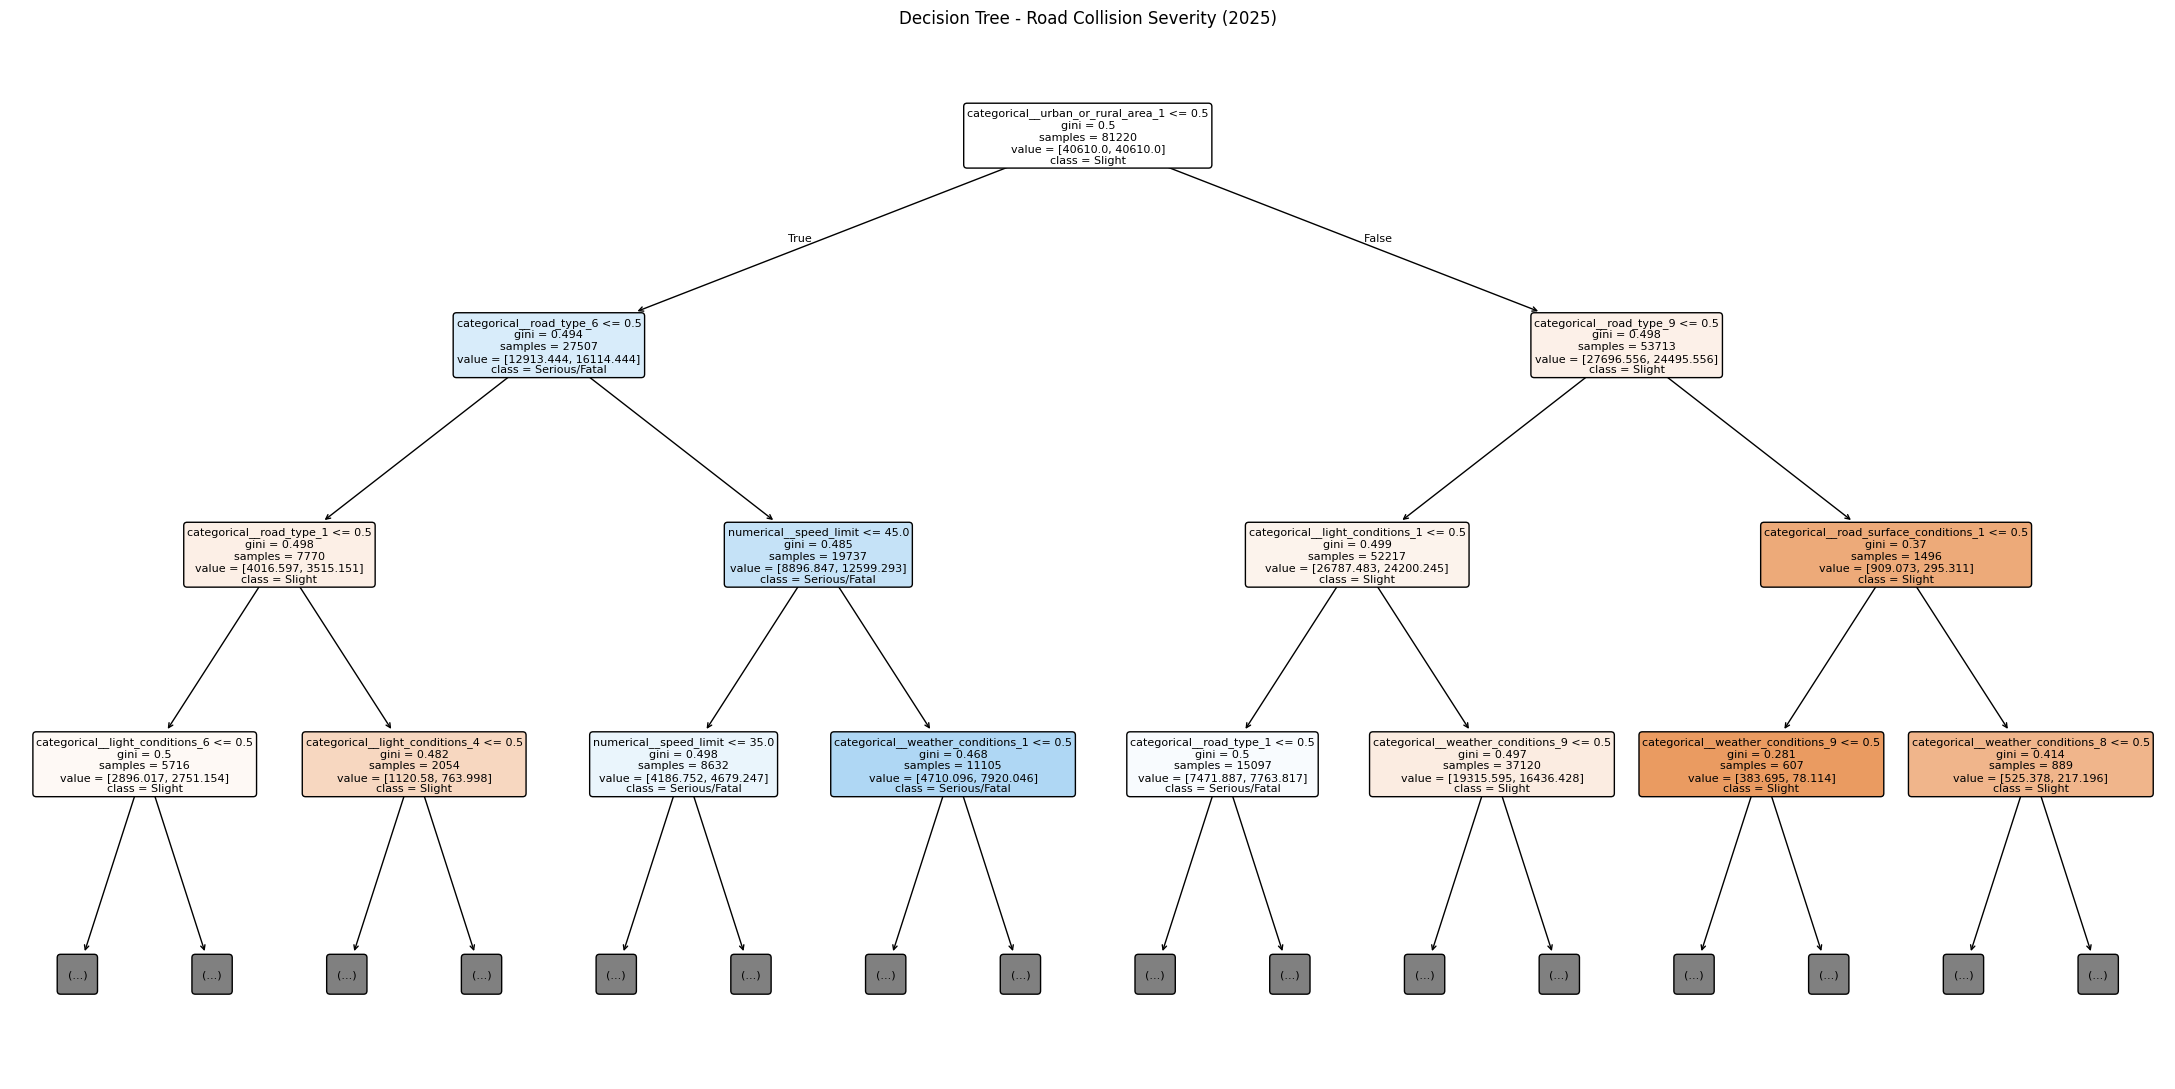

In [ ]:


import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree_classifier = model.named_steps["classifier"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

plt.figure(figsize=(22, 11))

plot_tree(
    tree_classifier,
    feature_names=feature_names,
    class_names=["Slight", "Serious/Fatal"],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree - Road Collision Severity (2025)")
plt.tight_layout()
plt.show()
